# Tugas 1 - Klasifikasi Suara dengan kNN
Target label : male dan female.

In [1]:
# Langkah 1 - Load dan Inspeksi Data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

data = pd.read_csv('data/voice.csv')
display(data.head())
print('Ukuran data:', data.shape)
print('Jumlah nilai kosong:', data.isna().sum().sum())
print('Jumlah duplikat:', data.duplicated().sum())
data = data.drop_duplicates().reset_index(drop=True)
print('Ukuran setelah dibersihkan:', data.shape)
print(data['label'].value_counts())

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


Ukuran data: (3168, 21)
Jumlah nilai kosong: 0
Jumlah duplikat: 2
Ukuran setelah dibersihkan: (3166, 21)
label
male      1583
female    1583
Name: count, dtype: int64


In [2]:
# Langkah 2 - Pisahkan Fitur, Target, dan Data Uji
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV

X = data.drop(columns='label')
y = data['label']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
print('Data latih:', X_train.shape)
print('Data uji:', X_test.shape)

Data latih: (2216, 20)
Data uji: (950, 20)


In [ ]:
# Langkah 3 - Percobaan Pemilihan Fitur dan Nilai K
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# Seleksi fitur dan scaling dipelajari kembali pada setiap fold data latih.
pipeline = Pipeline([
    ('seleksi', SelectKBest(score_func=f_classif)),
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])
parameter = {
    'seleksi_k': list(range(1, X.shape[1] + 1)),
    'knn__n_neighbors': list(range(1, 31))
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pencarian = GridSearchCV(pipeline, parameter, scoring='accuracy', cv=cv, n_jobs=1)
pencarian.fit(X_train, y_train)

print('Parameter terbaik:', pencarian.best_params_)
print('Rata-rata akurasi validasi:', pencarian.best_score_)

Parameter terbaik: {'knn__n_neighbors': 3, 'seleksi__k': 9}
Rata-rata akurasi validasi: 0.9810505765359039


In [ ]:
# Langkah 4 - Tampilkan Hasil Percobaan Fitur
hasil_cv = pd.DataFrame(pencarian.cv_results_)
hasil_cv['Jumlah Fitur'] = hasil_cv['param_seleksi__k'].astype(int)
hasil_cv['K'] = hasil_cv['param_knn__n_neighbors'].astype(int)
hasil_cv['Akurasi Validasi'] = hasil_cv['mean_test_score']

# Ambil nilai k dengan skor validasi terbaik untuk setiap jumlah fitur.
hasil_fitur = (hasil_cv.sort_values(
    ['Akurasi Validasi', 'Jumlah Fitur', 'K'], ascending=[False, True, True]
).drop_duplicates('Jumlah Fitur').sort_values('Jumlah Fitur'))
display(hasil_fitur[['Jumlah Fitur', 'K', 'Akurasi Validasi']].reset_index(drop=True))

model = pencarian.best_estimator_
fitur_terpilih = X.columns[model.named_steps['seleksi'].get_support()].tolist()
k_terbaik = pencarian.best_params_['knn__n_neighbors']
jumlah_fitur_terbaik = pencarian.best_params_['seleksi_k']
print('Fitur terpilih:', fitur_terpilih)
print('Nilai K terbaik:', k_terbaik)

# Ranking dihitung hanya dari data latih.
ranking = pd.DataFrame({
    'Fitur': X.columns, 'Skor ANOVA': model.named_steps['seleksi'].scores_
}).sort_values('Skor ANOVA', ascending=False)
display(ranking.reset_index(drop=True))

,Jumlah Fitur,K,Akurasi Validasi
0,1,26,0.951267
1,2,5,0.968868
2,3,7,0.972477
3,4,6,0.976987
4,5,4,0.979694
5,6,3,0.981048
6,7,8,0.980599
7,8,8,0.979244
8,9,3,0.981051
9,10,3,0.979247


Fitur terpilih: ['meanfreq', 'sd', 'median', 'Q25', 'IQR', 'sp.ent', 'sfm', 'centroid', 'meanfun']
Nilai K terbaik: 3


,Fitur,Skor ANOVA
0,meanfun,5050.014732
1,IQR,1393.940273
2,Q25,765.719143
3,sp.ent,674.916870
4,sd,655.698761
5,sfm,321.418588
6,centroid,271.256707
7,meanfreq,271.256707
8,median,182.107405
9,mindom,84.567529


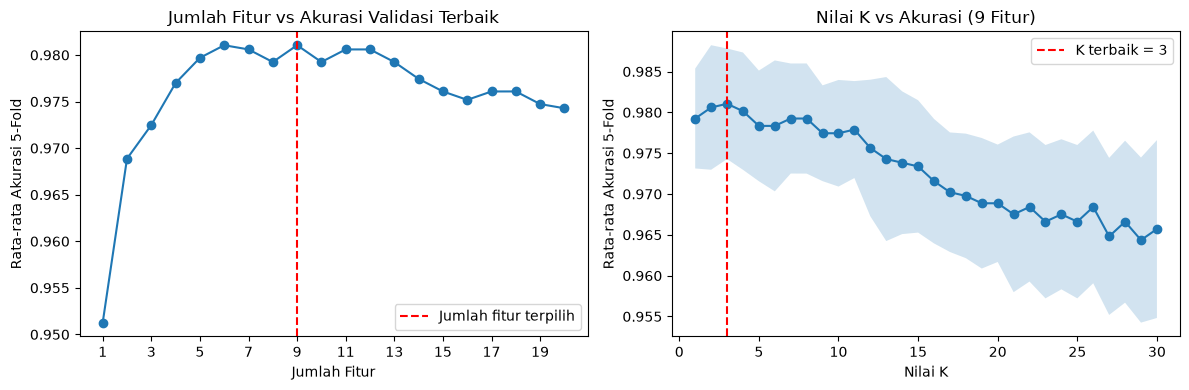

In [5]:
# Langkah 5 - Grafik Analisis Jumlah Fitur dan Nilai K
hasil_k = hasil_cv[hasil_cv['Jumlah Fitur'] == jumlah_fitur_terbaik].sort_values('K')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hasil_fitur['Jumlah Fitur'], hasil_fitur['Akurasi Validasi'], marker='o')
axes[0].axvline(jumlah_fitur_terbaik, color='red', linestyle='--', label='Jumlah fitur terpilih')
axes[0].set_title('Jumlah Fitur vs Akurasi Validasi Terbaik')
axes[0].set_xlabel('Jumlah Fitur')
axes[0].set_ylabel('Rata-rata Akurasi 5-Fold')
axes[0].set_xticks(range(1, X.shape[1] + 1, 2))
axes[0].legend()

axes[1].plot(hasil_k['K'], hasil_k['Akurasi Validasi'], marker='o')
axes[1].fill_between(hasil_k['K'],
                     hasil_k['Akurasi Validasi'] - hasil_k['std_test_score'],
                     hasil_k['Akurasi Validasi'] + hasil_k['std_test_score'], alpha=0.2)
axes[1].axvline(k_terbaik, color='red', linestyle='--', label=f'K terbaik = {k_terbaik}')
axes[1].set_title(f'Nilai K vs Akurasi ({jumlah_fitur_terbaik} Fitur)')
axes[1].set_xlabel('Nilai K')
axes[1].set_ylabel('Rata-rata Akurasi 5-Fold')
axes[1].legend()
plt.tight_layout()
plt.show()

Akurasi data latih: 0.9896209386281588
Akurasi data uji: 0.9757894736842105
Laporan Klasifikasi:
              precision    recall  f1-score   support

      female     0.9809    0.9705    0.9757       475
        male     0.9708    0.9811    0.9759       475

    accuracy                         0.9758       950
   macro avg     0.9758    0.9758    0.9758       950
weighted avg     0.9758    0.9758    0.9758       950



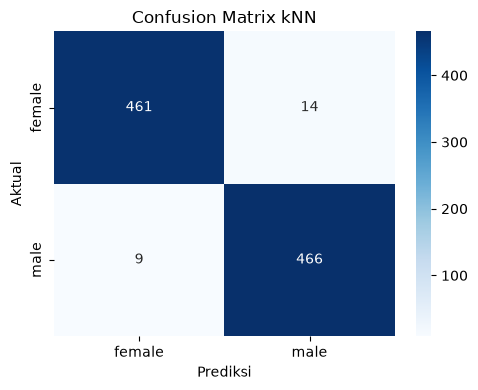

In [6]:
# Langkah 6 - Evaluasi Model Terpilih pada Data Uji
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = model.predict(X_test)
akurasi_uji = accuracy_score(y_test, y_pred)
print('Akurasi data latih:', model.score(X_train, y_train))
print('Akurasi data uji:', akurasi_uji)
print('Laporan Klasifikasi:')
print(classification_report(y_test, y_pred, digits=4, zero_division=0))

labels = ['female', 'male']
cm = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix kNN')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.tight_layout()
plt.show()

Fitur terbaik : meanfreq, sd, median, Q25, IQR, sp.ent, sfm, centroid, meanfun, dengan k = 3.

Rata-rata akurasi validasi:  98.11% dan akurasi data uji 97.58%.